# 08 — Explainability with Grad-CAM
Modelin elin hangi bölgelerine baktığını görmek istiyoruz. Beklenen: büyüme plakaları (falanks ve radius/ulna uçları) ve bilek (karpal) kemikleri — radyologların da kemik yaşı belirlerken baktığı yerler.

In [1]:
# On Colab: mount Drive and work from the project's notebooks folder
import os, sys
if "google.colab" in sys.modules and not os.getcwd().endswith("notebooks"):
    from google.colab import drive
    drive.mount("/content/drive")
    %cd /content/drive/MyDrive/bone-age/notebooks
%run 00_common.ipynb

Model: baseline_b0_384


C:\Users\MERT\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\autograd\graph.py:1072: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\cuda\CublasHandlePool.cpp:410.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


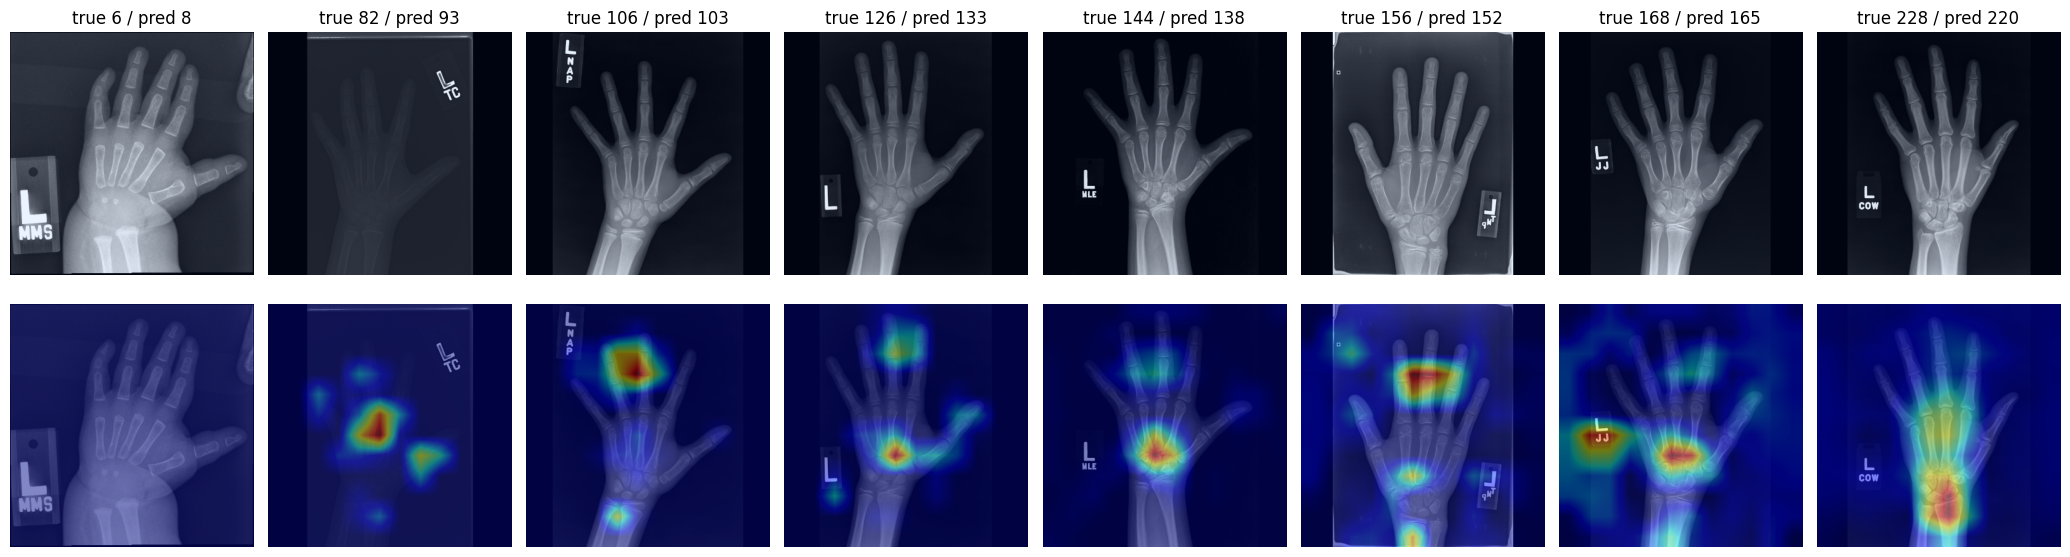

In [2]:
RUN = pd.read_json(OUTPUT_DIR / "experiments.json").query("runs.str.len() == 1").iloc[0]["runs"][0]
model, ckpt = load_model(RUN)
stats = ckpt["stats"]
df, _ = load_splits()
val = df[df["split"] == "val"].sort_values("boneage").reset_index(drop=True)
picks = val.iloc[np.linspace(0, len(val) - 1, 8).astype(int)].reset_index(drop=True)
ds = BoneAgeDataset(picks, get_transforms(False, ckpt["img_size"]), *stats)
print("Model:", RUN)

fig, axes = plt.subplots(2, len(picks), figsize=(2.6 * len(picks), 6))
for i in range(len(picks)):
    img, sex, _ = ds[i]
    cam, pred = grad_cam(model, img[None].to(DEVICE), sex[None].to(DEVICE))
    raw = img.permute(1, 2, 0).numpy()
    raw = (raw - raw.min()) / (raw.max() - raw.min())
    axes[0, i].imshow(raw)
    axes[0, i].set_title(f"true {picks.loc[i, 'boneage']:.0f} / pred {pred * stats[1] + stats[0]:.0f}")
    axes[1, i].imshow(raw)
    axes[1, i].imshow(cam, cmap="jet", alpha=0.45)
    for ax in axes[:, i]:
        ax.axis("off")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "gradcam.png", dpi=110, bbox_inches="tight")
plt.show()

## Yorum (Findings)
- **5–15 yaş:** Isı haritası çoğunlukla **metakarp başları / proksimal falanks eklemleri** (büyüme plakaları) ve **karpal (bilek) kemikleri** üzerinde yoğunlaşıyor. Radyologların Greulich-Pyle atlasında baktığı bölgeler de bunlar → model anlamlı anatomik ipuçları kullanıyor.
- **19 yaş (228 ay):** Odak **distal radius/ulna** (önkol kemiklerinin bilek ucu). Bu büyüme plakası en son kapanan plakadır → yetişkine yakın yaşlarda tam da bakılması gereken yer.
- **6 aylık bebek:** Harita neredeyse boş. Grad-CAM sadece tahmini **artıran** bölgeleri gösterir (ReLU). Çok küçük yaşta model tahmini aşağı çeken özelliklere (kemikleşmemiş karpal bölge) dayanıyor; bu yüzden pozitif katkı görünmüyor. Bu Grad-CAM'in regresyondaki bilinen bir sınırlaması.
- **Uyarı (shortcut / kestirme öğrenme):** 168 aylık örnekte model kısmen **"L JJ" işaretçisine** de bakıyor. Etiketler/işaretçiler hastaneye veya teknisyene göre değişiyorsa model bunları yaşla ilişkilendirebilir. İyileştirme: el bölgesini kırpmak (hand segmentation/crop) veya işaretçileri maskelemek.